In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
sns.set()
import matplotlib.pyplot as plt

from sklearn import linear_model
import lightgbm as lgbm

from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold

In [2]:
X_train = pd.read_csv('../data/X_train.csv',index_col='ROW_ID')
X_test = pd.read_csv('../data/X_test.csv',index_col='ROW_ID')

y_train = pd.read_csv('../data/y_train.csv',index_col='ROW_ID')
y_train = (y_train['target'] > 0).astype(int)
sample_submission = pd.read_csv('../data/sample_submission.csv',index_col='ROW_ID')
total_data = pd.concat([X_train,y_train],axis=1)
preds=pd.read_csv('../data/final_model_train_predictions.csv',index_col='ROW_ID')

In [3]:
no_match=total_data.copy()
no_match = no_match[no_match["target"] != preds["pred_bin"]]
match=total_data.copy()
match = match[match["target"] == preds["pred_bin"]]
print(no_match.head())

               TS     ALLOCATION    RET_20    RET_19    RET_18    RET_17  \
ROW_ID                                                                     
2       DATE_0001  ALLOCATION_03 -0.016587 -0.004517 -0.005306  0.004314   
3       DATE_0001  ALLOCATION_04 -0.005344  0.002790  0.006937 -0.004246   
4       DATE_0001  ALLOCATION_05 -0.010506 -0.005491  0.007752 -0.012299   
6       DATE_0001  ALLOCATION_07 -0.001348  0.000755  0.000806  0.003347   
8       DATE_0001  ALLOCATION_09  0.003805  0.002004 -0.001503  0.000572   

          RET_16    RET_15    RET_14    RET_13  ...  SIGNED_VOLUME_7  \
ROW_ID                                          ...                    
2       0.006471 -0.005868 -0.005030 -0.001488  ...         0.452482   
3      -0.005051 -0.000330 -0.000117 -0.005209  ...        -0.565114   
4       0.002191  0.003282  0.000495 -0.003489  ...         0.757707   
6       0.000798 -0.001033  0.001150  0.001335  ...        -1.029506   
8       0.003247 -0.001319  0.00067

In [4]:
print(f"Number of mismatches between actual and predicted: {len(no_match)} out of total {len(total_data['target'])} samples. {len(no_match)/len(total_data['target'])*100:.2f}% of the data.")

Number of mismatches between actual and predicted: 243708 out of total 527073 samples. 46.24% of the data.


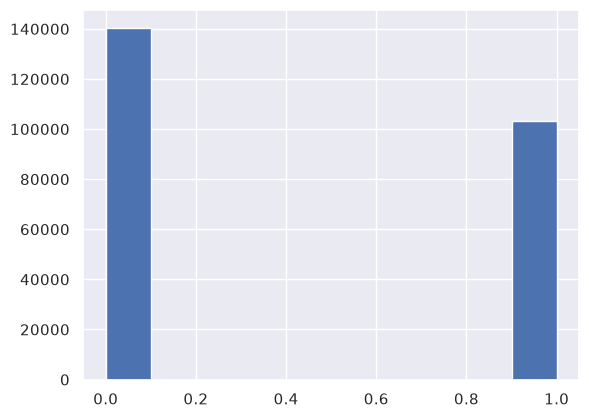

In [5]:
plt.hist(no_match["target"], bins=10)
plt.show()

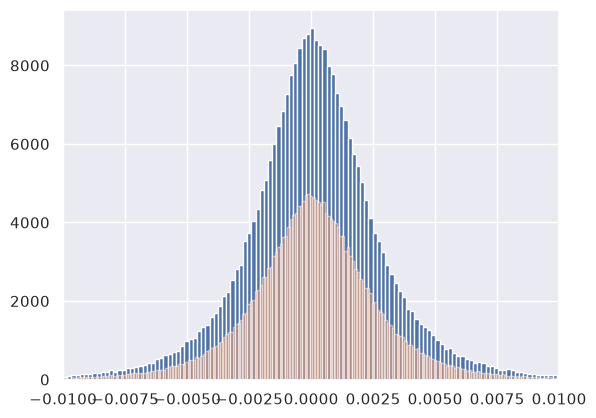

Number of zeros in RET_1 for mismatches: 0 out of total 243708 mismatches. 0.00% of the mismatches.


In [6]:
plt.hist(match["RET_1"], bins=1000)
plt.hist(no_match['RET_1'], bins=1000, alpha=0.5)
plt.xlim(-0.01,0.01)
plt.show()
num_zeros=len(no_match[no_match['RET_1']==0])
print(f"Number of zeros in RET_1 for mismatches: {num_zeros} out of total {len(no_match)} mismatches. {num_zeros/len(no_match)*100:.2f}% of the mismatches.")

In [7]:
large_no=len(no_match[np.abs(no_match['RET_1'])>0.01])
large_total=len(total_data[np.abs(total_data['RET_1'])>0.01])
print(f"Number of large RET_1 values (abs>0.01) for mismatches: {large_no} out of total {large_total} samples. {100-large_no/large_total*100:.2f}% of the large RET_1 values.")

Number of large RET_1 values (abs>0.01) for mismatches: 2241 out of total 5404 samples. 58.53% of the large RET_1 values.


In [8]:
total_ret_1 = len(total_data['RET_1'])
no_match_ret_1 = len(no_match['RET_1'])
print(100-len(no_match)/len(total_data)*100)
print(f"Total RET_1 values: {total_ret_1}, Mismatched RET_1 values: {no_match_ret_1}, Percentage of mismatched RET_1 values: {100-no_match_ret_1/total_ret_1*100:.2f}%")

53.76200260684952
Total RET_1 values: 527073, Mismatched RET_1 values: 243708, Percentage of mismatched RET_1 values: 53.76%


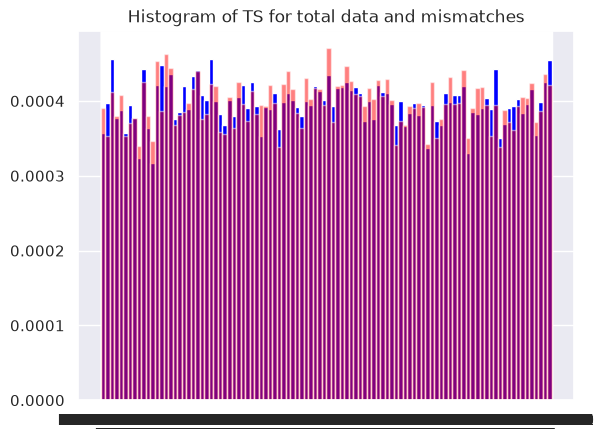

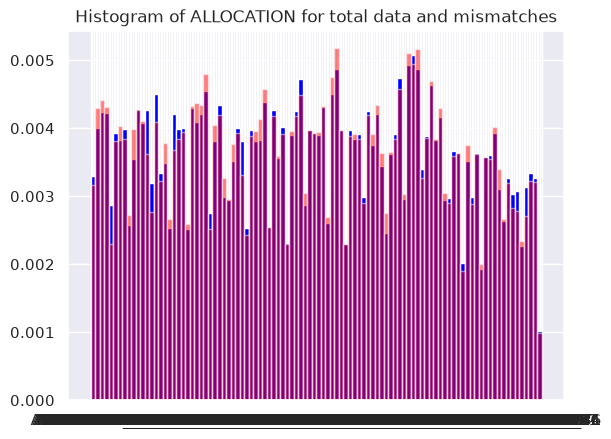

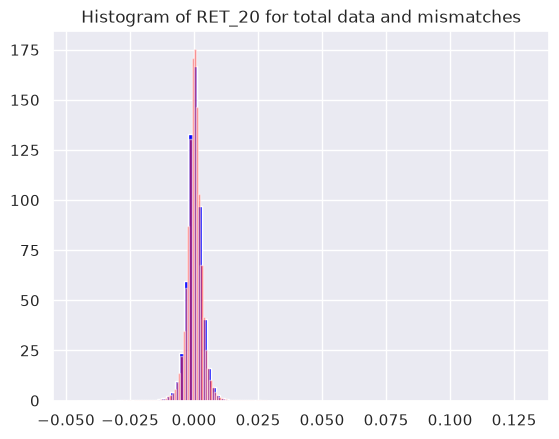

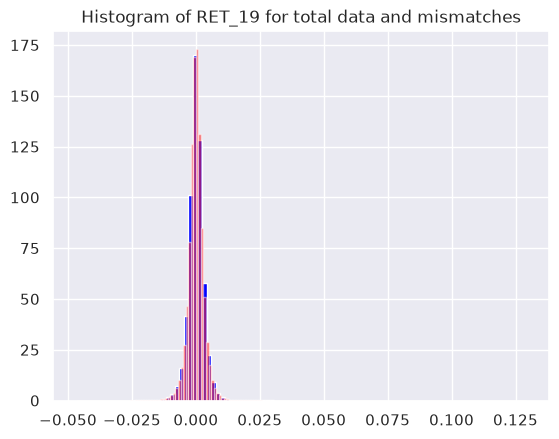

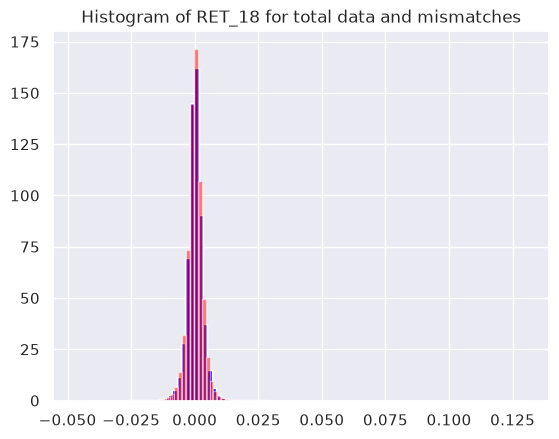

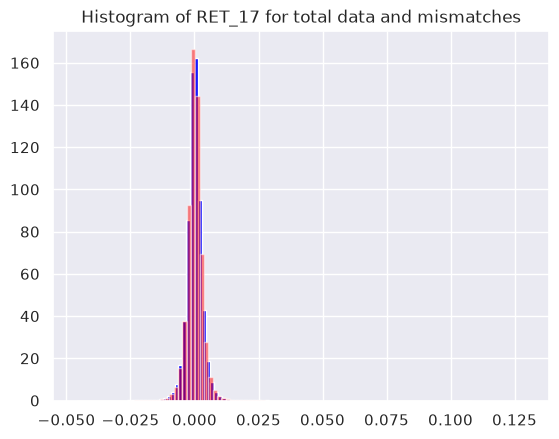

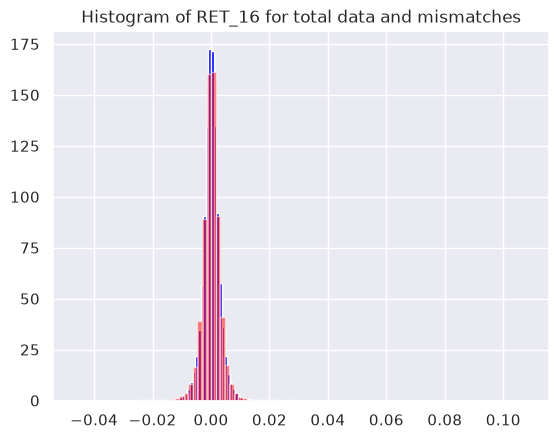

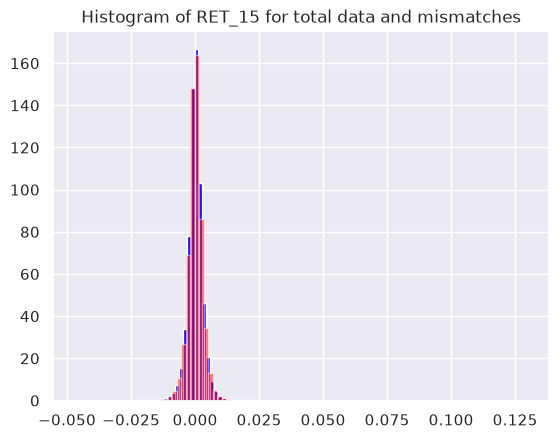

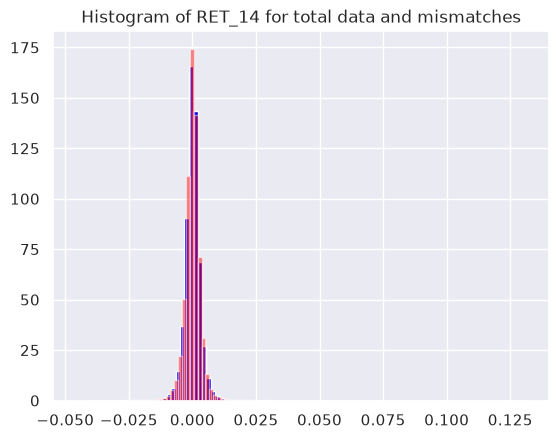

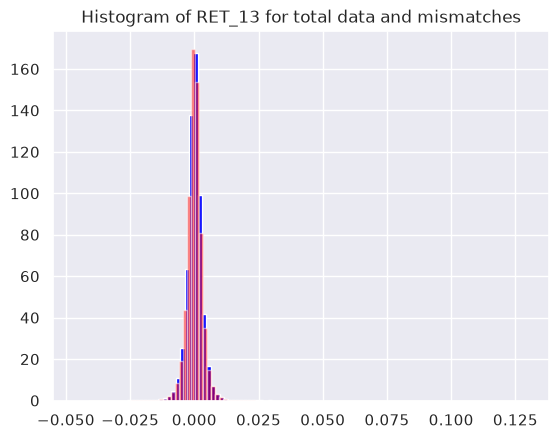

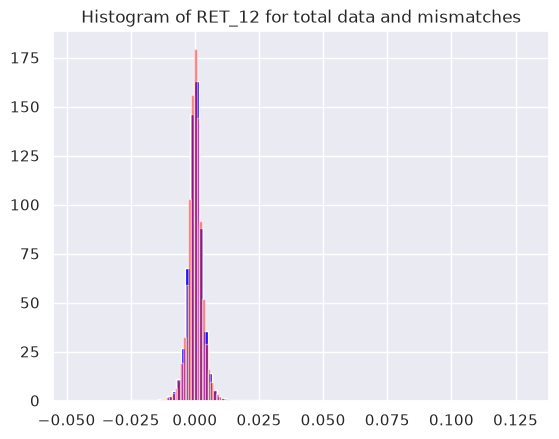

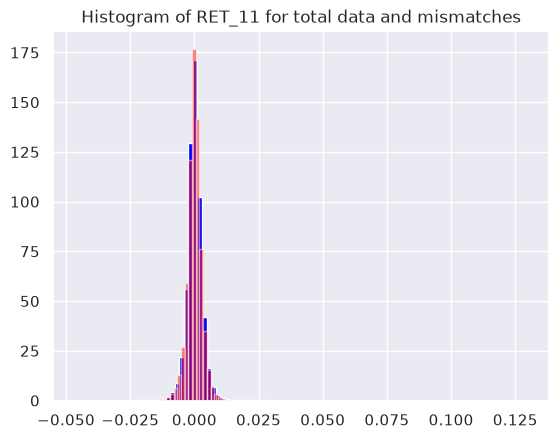

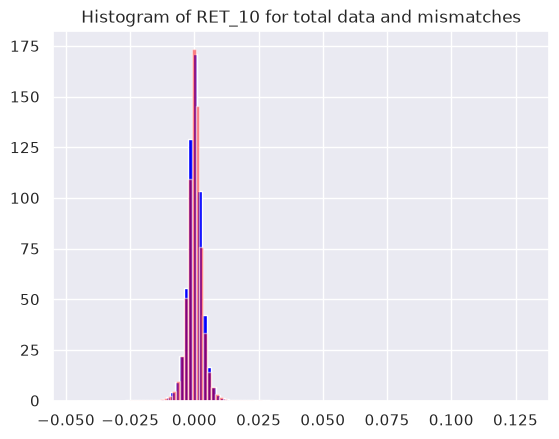

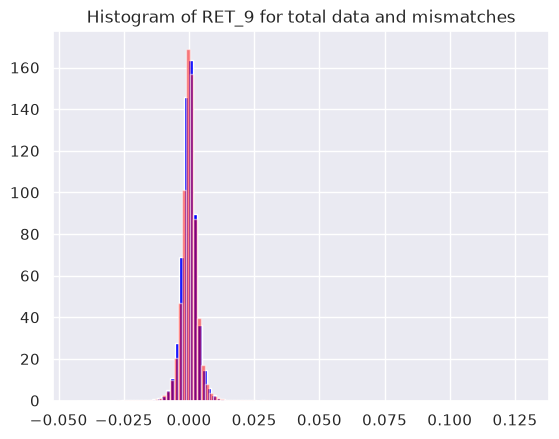

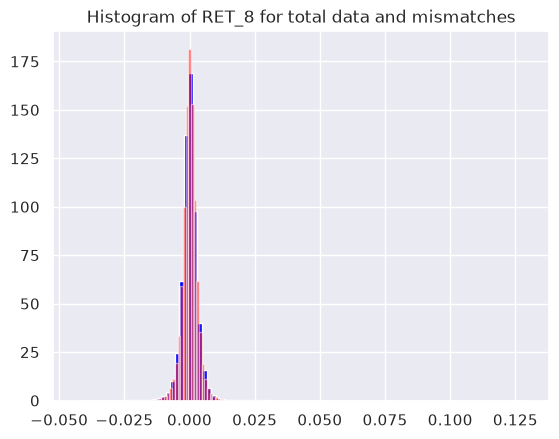

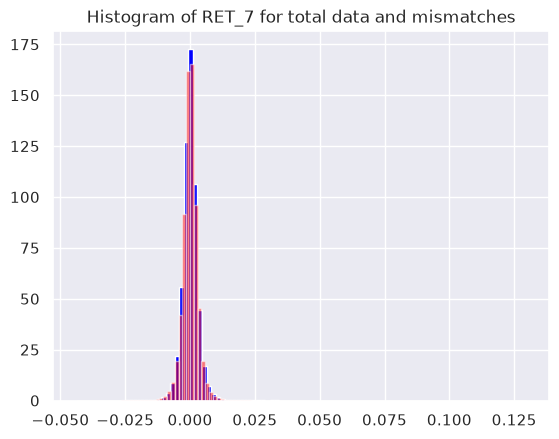

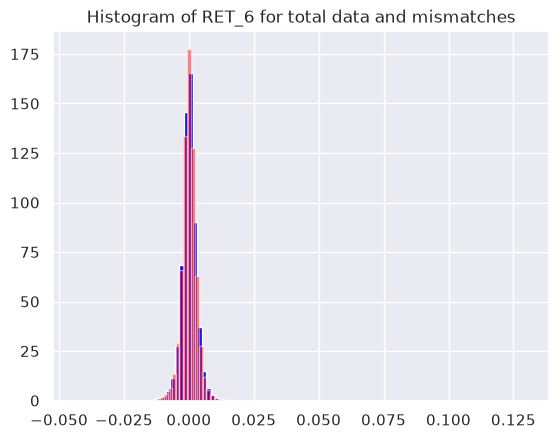

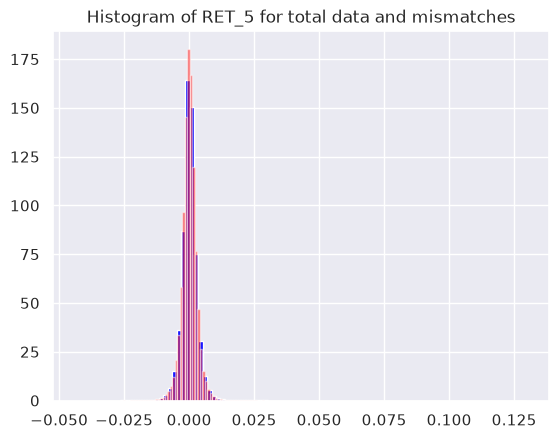

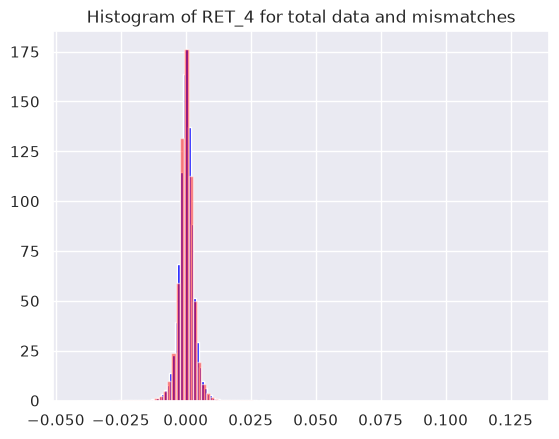

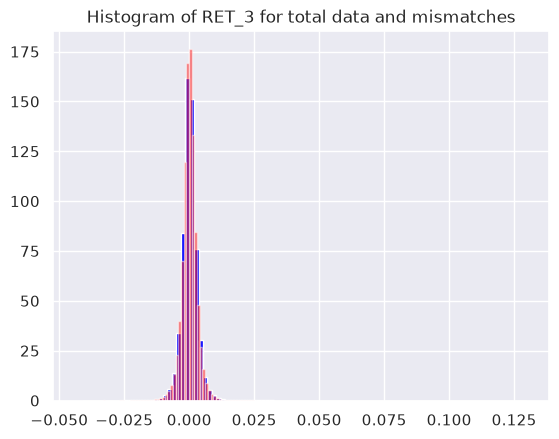

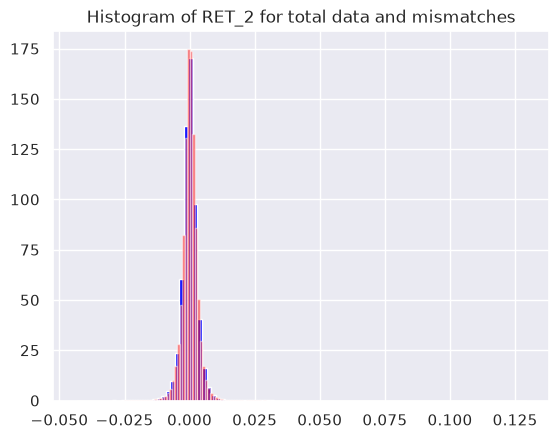

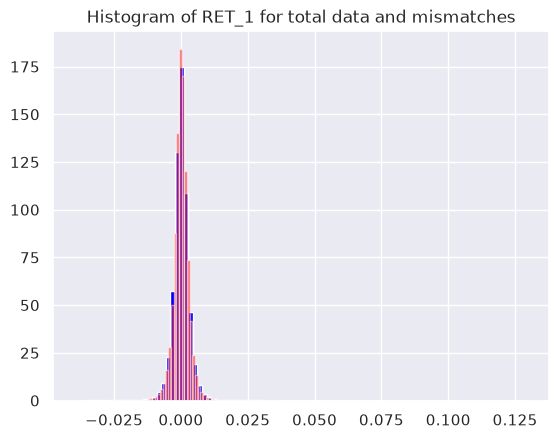

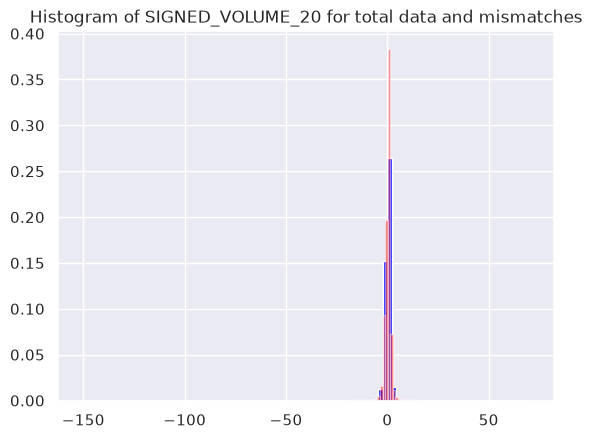

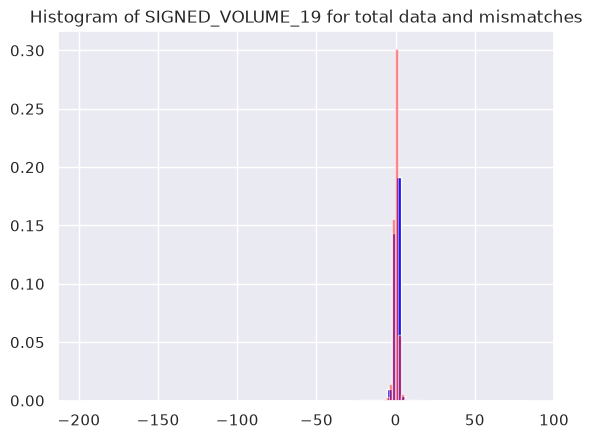

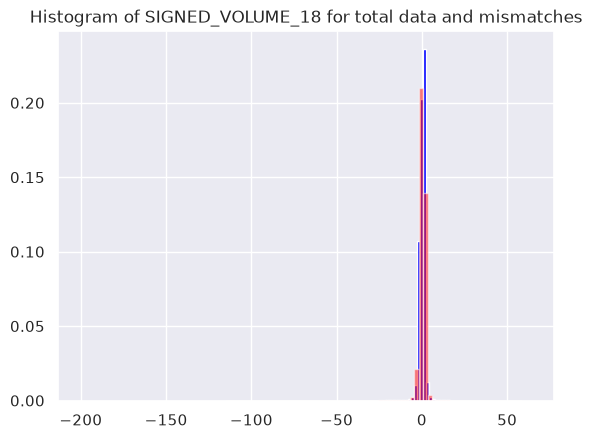

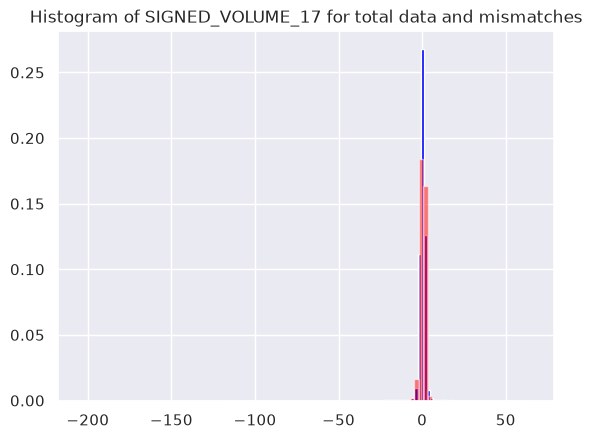

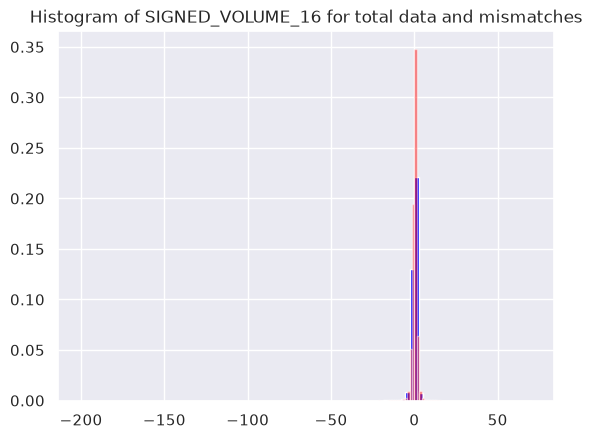

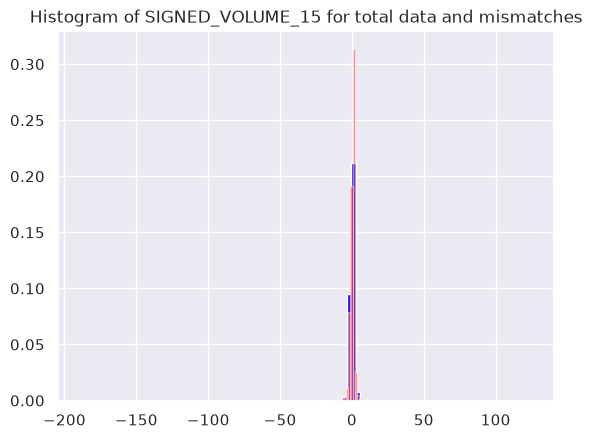

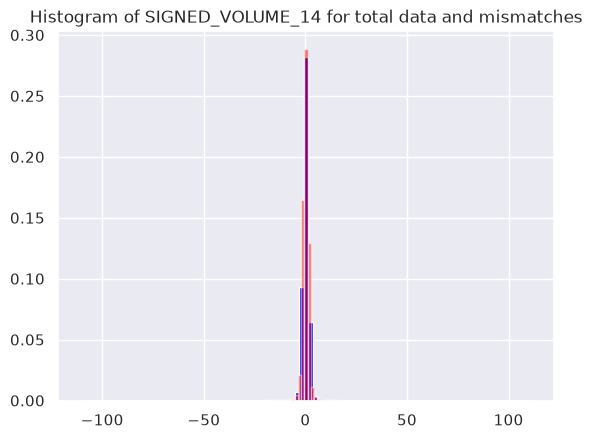

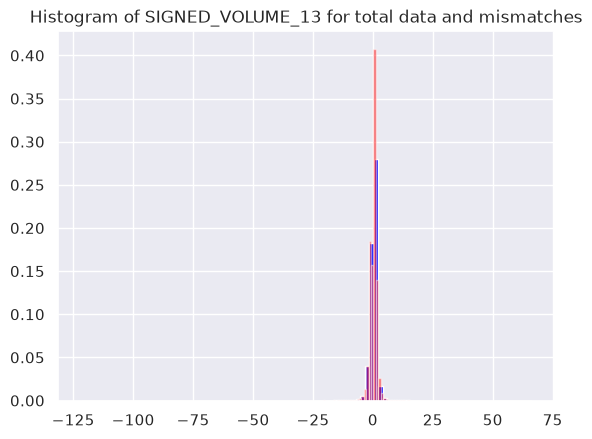

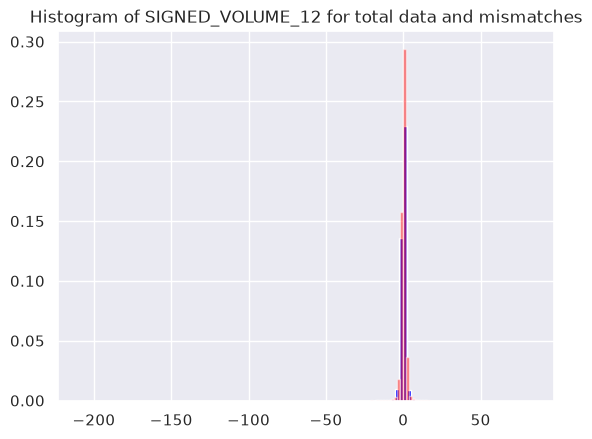

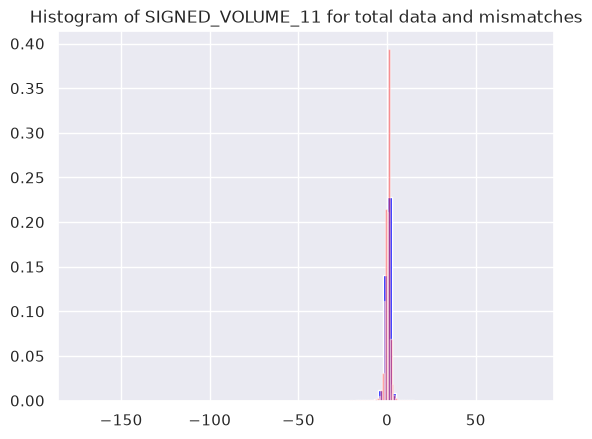

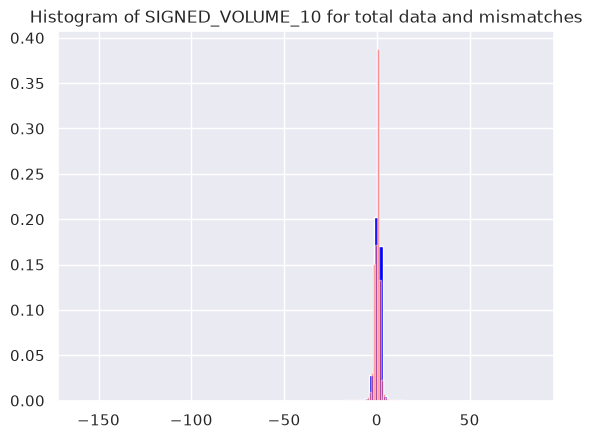

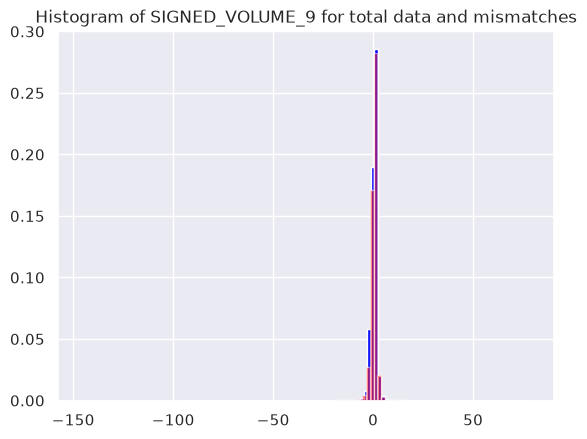

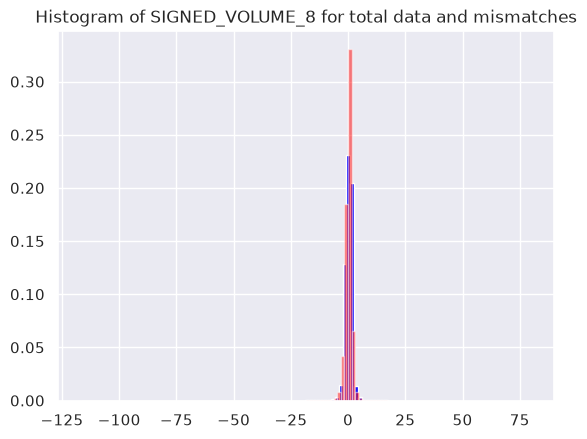

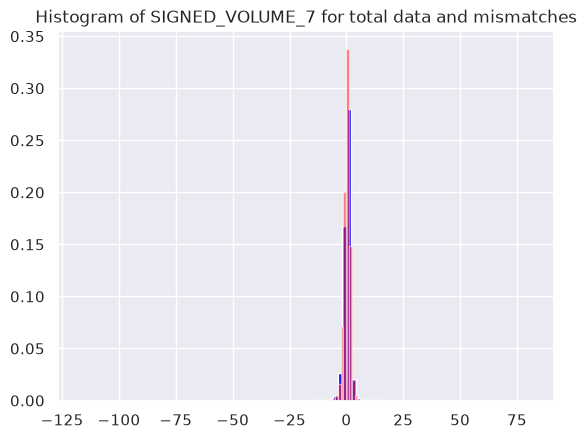

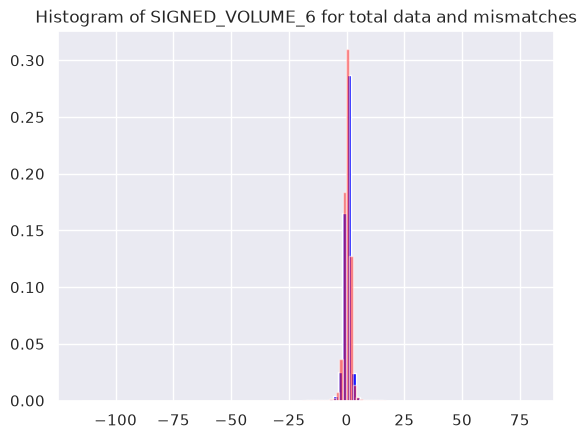

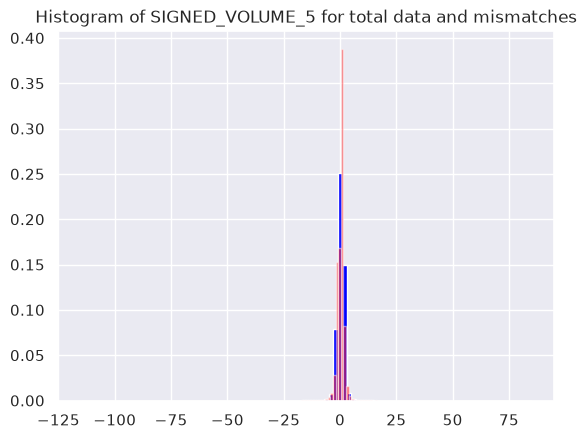

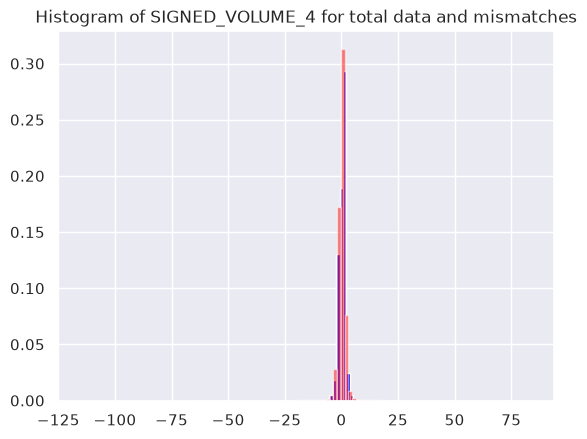

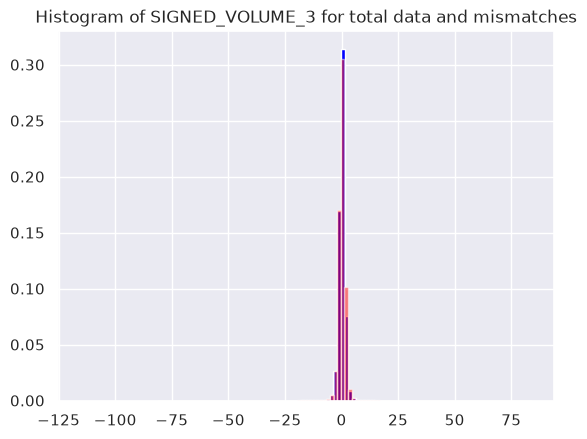

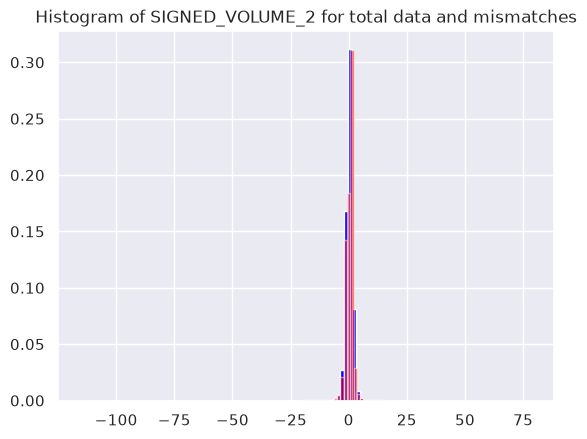

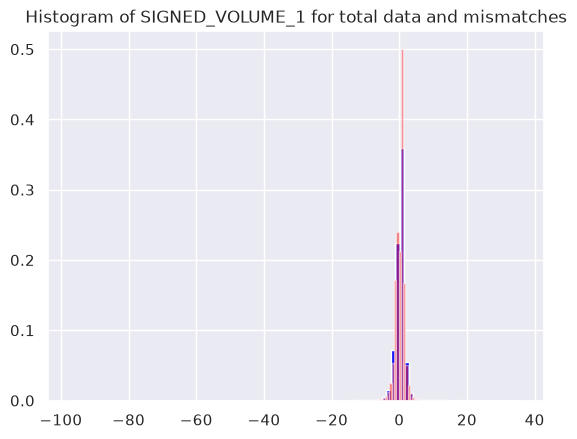

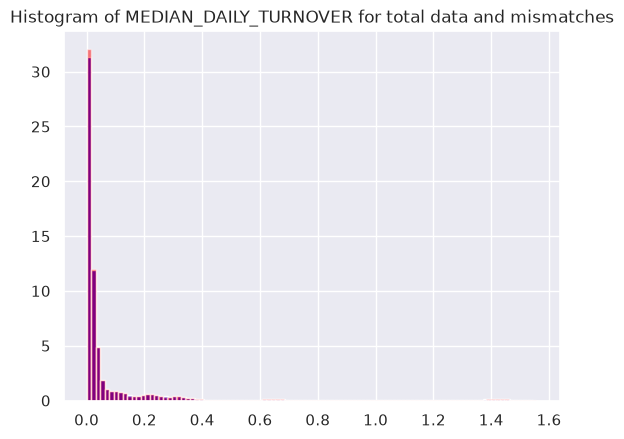

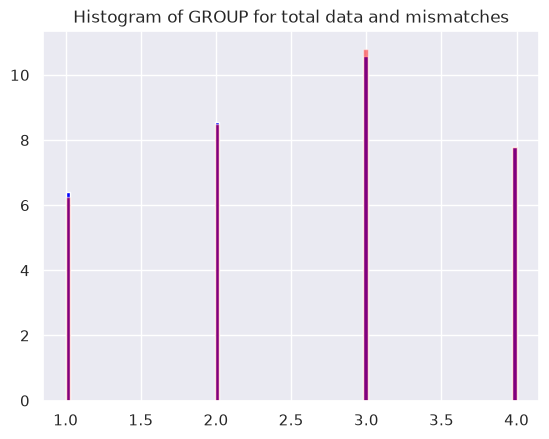

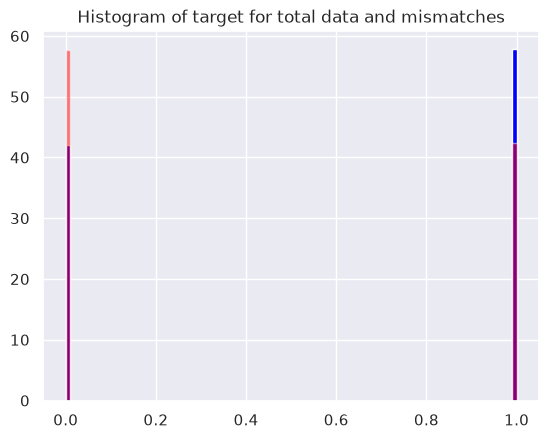

In [9]:
for column in total_data.columns:
    plt.hist(match[column], bins=100,color="blue",density=True)
    plt.hist(no_match[column], bins=100,color="red",density=True, alpha=0.5)
    plt.title(f"Histogram of {column} for total data and mismatches")
    plt.show()

In [10]:
for col in total_data.columns:
    a = match[col].dropna()
    b = no_match[col].dropna()

    if not (pd.api.types.is_numeric_dtype(a) and
            pd.api.types.is_numeric_dtype(b)):
        continue

    pooled_std = np.sqrt((a.var() + b.var()) / 2)

    effect = (
        (b.mean() - a.mean()) / pooled_std
        if pooled_std > 0 else 0
    )

    print(f"{col:30s} {effect:+.4f}")


RET_20                         -0.0027
RET_19                         -0.0046
RET_18                         +0.0013
RET_17                         +0.0039
RET_16                         -0.0010
RET_15                         -0.0069
RET_14                         -0.0058
RET_13                         -0.0105
RET_12                         -0.0058
RET_11                         -0.0039
RET_10                         -0.0033
RET_9                          -0.0057
RET_8                          -0.0048
RET_7                          -0.0156
RET_6                          -0.0073
RET_5                          -0.0129
RET_4                          +0.0097
RET_3                          -0.0049
RET_2                          +0.0030
RET_1                          -0.0072
SIGNED_VOLUME_20               -0.0057
SIGNED_VOLUME_19               -0.0068
SIGNED_VOLUME_18               -0.0043
SIGNED_VOLUME_17               -0.0089
SIGNED_VOLUME_16               -0.0012
SIGNED_VOLUME_15         

In [11]:
from scipy.stats import ks_2samp

results = []

for col in total_data.columns:
    a = match[col].dropna()
    b = no_match[col].dropna()

    if not (pd.api.types.is_numeric_dtype(a) and
            pd.api.types.is_numeric_dtype(b)):
        continue

    ks, p = ks_2samp(a, b)

    results.append((col, ks, p))

print(pd.DataFrame(
    results,
    columns=["feature", "KS", "p_value"]
).sort_values("KS", ascending=False))

                  feature        KS       p_value
42                 target  0.155995  0.000000e+00
40  MEDIAN_DAILY_TURNOVER  0.012028  8.844632e-17
19                  RET_1  0.009259  3.484124e-10
15                  RET_5  0.008276  3.187557e-08
39        SIGNED_VOLUME_1  0.008120  2.069452e-02
5                  RET_15  0.007362  1.353238e-06
41                  GROUP  0.007347  1.432326e-06
7                  RET_13  0.007152  3.003640e-06
0                  RET_20  0.007148  3.059244e-06
16                  RET_4  0.006690  1.606792e-05
18                  RET_2  0.006357  5.006307e-05
9                  RET_11  0.006339  5.326718e-05
13                  RET_7  0.006022  1.488665e-04
14                  RET_6  0.006014  1.523021e-04
11                  RET_9  0.005981  1.690507e-04
12                  RET_8  0.005533  6.536917e-04
2                  RET_18  0.005324  1.185299e-03
10                 RET_10  0.005282  1.332412e-03
35        SIGNED_VOLUME_5  0.005211  1.617296e-03


In [12]:
total_data["MODEL_WRONG"] = (
    total_data["target"] != preds["pred_bin"]
).astype(int)

total_data["RET1_DECILE"] = pd.qcut(
    total_data["RET_1"],
    10,
    labels=False,
    duplicates="drop"
)

print(total_data.groupby("RET1_DECILE")["MODEL_WRONG"].agg(["mean", "count"]))

                 mean  count
RET1_DECILE                 
0            0.451393  52708
1            0.461931  52707
2            0.466921  52707
3            0.468040  52707
4            0.469739  52708
5            0.468363  52707
6            0.468856  52707
7            0.464151  52707
8            0.462709  52707
9            0.441698  52708


In [13]:
total_data["TURN_DECILE"] = pd.qcut(
    total_data["MEDIAN_DAILY_TURNOVER"],
    10,
    labels=False,
    duplicates="drop"
)

print(total_data.groupby("TURN_DECILE")["MODEL_WRONG"].agg(["mean", "count"]))

                 mean  count
TURN_DECILE                 
0.0          0.468029  52345
1.0          0.472985  52342
2.0          0.469414  52344
3.0          0.466271  52343
4.0          0.461868  52344
5.0          0.463921  52343
6.0          0.461743  52343
7.0          0.462517  52344
8.0          0.458781  52343
9.0          0.438331  52344


In [14]:
total_data["MODEL_WRONG"] = (
    total_data["target"] != preds["pred_bin"]
).astype(int)

total_data.groupby(
    pd.qcut(preds["pred_prob"], 10, labels=False)
)["MODEL_WRONG"].mean()

pred_prob
0    0.411171
1    0.466731
2    0.482517
3    0.488474
4    0.495598
5    0.488133
6    0.475990
7    0.467585
8    0.448309
9    0.399294
Name: MODEL_WRONG, dtype: float64

In [15]:
mask = preds["pred_prob"].between(0.45, 0.55)

m = total_data.loc[mask & (total_data["MODEL_WRONG"] == 0)]
w = total_data.loc[mask & (total_data["MODEL_WRONG"] == 1)]

results = []

for col in total_data.columns:
    a = m[col].dropna()
    b = w[col].dropna()

    if pd.api.types.is_numeric_dtype(a) and pd.api.types.is_numeric_dtype(b):
        ks, p = ks_2samp(a, b)
        results.append((col, ks, p))

print(pd.DataFrame(
    results,
    columns=["feature", "KS", "p_value"]
).sort_values("KS", ascending=False))

                  feature        KS       p_value
43            MODEL_WRONG  1.000000  0.000000e+00
42                 target  0.124152  0.000000e+00
41                  GROUP  0.009109  3.572093e-09
15                  RET_5  0.006964  1.539471e-05
40  MEDIAN_DAILY_TURNOVER  0.006128  2.331534e-04
35        SIGNED_VOLUME_5  0.006100  2.386449e-04
45            TURN_DECILE  0.006038  3.039144e-04
33        SIGNED_VOLUME_7  0.005735  6.793609e-04
32        SIGNED_VOLUME_8  0.005409  1.642762e-03
37        SIGNED_VOLUME_3  0.005253  2.461369e-03
18                  RET_2  0.005166  3.063305e-03
20       SIGNED_VOLUME_20  0.005067  4.336669e-03
0                  RET_20  0.005008  4.527555e-03
16                  RET_4  0.004992  4.710586e-03
34        SIGNED_VOLUME_6  0.004939  5.351594e-03
36        SIGNED_VOLUME_4  0.004894  5.960004e-03
21       SIGNED_VOLUME_19  0.004869  6.537411e-03
24       SIGNED_VOLUME_16  0.004848  6.648069e-03
23       SIGNED_VOLUME_17  0.004747  8.412566e-03


In [16]:
print(total_data.loc[
    preds["pred_prob"].between(0.45, 0.55)
].groupby("GROUP")["MODEL_WRONG"].agg(["mean", "count"]))

           mean   count
GROUP                  
1      0.461774   94843
2      0.467117  123939
3      0.476936  154612
4      0.469943  113784


In [17]:
mask = preds["pred_prob"].between(0.45, 0.55)

tmp = total_data.loc[mask].copy()

tmp["RET5_DECILE"] = pd.qcut(
    tmp["RET_5"],
    10,
    labels=False,
    duplicates="drop"
)

print(tmp.groupby("RET5_DECILE")["MODEL_WRONG"].agg(["mean", "count"]))

                 mean  count
RET5_DECILE                 
0            0.469231  48718
1            0.474527  48718
2            0.477236  48718
3            0.472546  48717
4            0.470976  48718
5            0.469231  48718
6            0.469241  48717
7            0.467035  48718
8            0.465044  48718
9            0.463463  48718


In [18]:
tmp = total_data.loc[
    preds["pred_prob"].between(0.45, 0.55)
].copy()

tmp["CONF_DECILE"] = pd.qcut(
    preds.loc[tmp.index, "pred_prob"],
    5,
    labels=False
)

print(tmp.groupby(["GROUP", "CONF_DECILE"])["MODEL_WRONG"].mean().unstack())

CONF_DECILE         0         1         2         3         4
GROUP                                                        
1            0.436937  0.489183  0.489068  0.461586  0.429803
2            0.445509  0.478099  0.494072  0.477242  0.441415
3            0.461840  0.490492  0.494027  0.484592  0.455099
4            0.450112  0.485209  0.488135  0.478058  0.445339


In [19]:
tmp = total_data.loc[
    preds["pred_prob"].between(0.45, 0.55)
].copy()

tmp["RET45_SAME_SIGN"] = (
    np.sign(tmp["RET_4"]) == np.sign(tmp["RET_5"])
).astype(int)

print(tmp.groupby("RET45_SAME_SIGN")["MODEL_WRONG"].agg(["mean", "count"]))

                     mean   count
RET45_SAME_SIGN                  
0                0.468971  239209
1                0.470704  247969


In [20]:
tmp = total_data.copy()

tmp["ERROR"] = tmp["target"] - preds["pred_prob"]

tmp["CONF_DECILE"] = pd.qcut(
    preds["pred_prob"], 10, labels=False
)

print(tmp.groupby("CONF_DECILE")["ERROR"].agg(["mean", "std", "count"]))

                 mean       std  count
CONF_DECILE                           
0           -0.048576  0.490866  52708
1           -0.012529  0.498880  52707
2           -0.006044  0.499679  52707
3           -0.007603  0.499877  52707
4           -0.000599  0.499987  52708
5            0.002377  0.499867  52707
6            0.007609  0.499421  52707
7            0.008278  0.498930  52707
8            0.017487  0.497280  52707
9            0.039734  0.488783  52708


In [21]:
p = preds["pred_prob"]

for k in [0.25, 0.5, 0.75]:
    p_cal = 0.5 + k * (p - 0.5)
    pred_cal = (p_cal >= 0.5).astype(int)

    print(
        k,
        (pred_cal == total_data["target"]).mean()
    )

0.25 0.537422709947199
0.5 0.537422709947199
0.75 0.537422709947199


In [22]:
tmp = total_data.copy()

tmp["CONF_ERROR"] = tmp["target"] - preds["pred_prob"]

tmp["RET1_DECILE"] = pd.qcut(
    tmp["RET_1"], 10, labels=False
)

print(tmp.groupby("RET1_DECILE")["CONF_ERROR"].agg(["mean", "count"]))

                 mean  count
RET1_DECILE                 
0           -0.008969  52708
1           -0.002035  52707
2           -0.002109  52707
3           -0.001390  52707
4            0.000119  52708
5            0.000531  52707
6            0.001222  52707
7            0.002703  52707
8            0.001563  52707
9            0.008499  52708


In [23]:
p = preds["pred_prob"]

for k in [0.02, 0.05, 0.10, 0.20]:
    adj = p - k * total_data["RET_1"]
    pred = (adj >= 0.5).astype(int)

    print(k, (pred == total_data["target"]).mean())

0.02 0.5374284017583902
0.05 0.5374530662735523
0.1 0.5374435799215669
0.2 0.537494806222288


In [24]:
p = preds["pred_prob"]

for k in [0.25, 0.5, 1.0, 2.0, 3.0, 5.0]:
    adj = p - k * total_data["RET_1"]
    pred = (adj >= 0.5).astype(int)
    print(k, (pred == total_data["target"]).mean())

0.25 0.5374853198703026
0.5 0.5375972588237303
1.0 0.5379444593063959
2.0 0.5388930945049357
3.0 0.539088513355835
5.0 0.537758526807482


In [25]:
p = preds["pred_prob"]

for lo, hi in [(0.45, 0.55), (0.475, 0.525), (0.49, 0.51)]:
    mask = p.between(lo, hi)

    base = (preds.loc[mask, "pred_bin"] == total_data.loc[mask, "target"]).mean()

    adj = p.loc[mask] - 2.0 * total_data.loc[mask, "RET_1"]
    new = ((adj >= 0.5).astype(int) == total_data.loc[mask, "target"]).mean()

    print(lo, hi, mask.sum(), base, new, new-base)

0.45 0.55 487178 0.5301470920279652 0.5315367278489587 0.0013896358209934956
0.475 0.525 342078 0.5176187886973147 0.5196767988587399 0.00205801016142515
0.49 0.51 153194 0.5092170711646671 0.5130292309098268 0.0038121597451596934


In [26]:
p = preds["pred_prob"]
mask = p.between(0.49, 0.51)

for k in np.arange(0, 4.25, 0.25):
    adj = p.loc[mask] - k * total_data.loc[mask, "RET_1"]
    acc = ((adj >= 0.5).astype(int) == total_data.loc[mask, "target"]).mean()
    print(f"{k:.2f}  {acc:.6f}")

0.00  0.508538
0.25  0.508760
0.50  0.509158
0.75  0.509713
1.00  0.510164
1.25  0.510353
1.50  0.511130
1.75  0.512337
2.00  0.513029
2.25  0.513023
2.50  0.513604
2.75  0.513747
3.00  0.513813
3.25  0.513871
3.50  0.514152
3.75  0.514433
4.00  0.514759


In [27]:
p = preds["pred_prob"]
mask = p.between(0.49, 0.51)

for k in [1.0, 2.0, 2.5, 3.0]:
    adj = p.loc[mask] - k * total_data.loc[mask, "RET_2"]
    acc = ((adj >= 0.5).astype(int) == total_data.loc[mask, "target"]).mean()
    print(k, acc)
    

1.0 0.5087601342089115
2.0 0.5077679282478426
2.5 0.5074676553912033
3.0 0.5077157068814706


In [28]:
p = preds["pred_prob"]
mask = p.between(0.49, 0.51)

for sign, name in [(1, "RET1 > 0"), (-1, "RET1 < 0")]:
    m = mask & (np.sign(total_data["RET_1"]) == sign)

    print(name, "n =", m.sum())

    for k in [0, 1, 2, 2.5, 3, 4]:
        adj = p.loc[m] - k * total_data.loc[m, "RET_1"]
        acc = ((adj >= 0.5).astype(int) == total_data.loc[m, "target"]).mean()
        print(k, round(acc, 6))

RET1 > 0 n = 65735
0 0.507142
1 0.509972
2 0.514977
2.5 0.516316
3 0.515327
4 0.51735
RET1 < 0 n = 87459
0 0.509587
1 0.510308
2 0.511565
2.5 0.511565
3 0.512675
4 0.512812


In [29]:
p = preds["pred_prob"]
mask = p.between(0.49, 0.51)

# Cross-sectional RET_1 percentile
ret1_rank = total_data.groupby("TS")["RET_1"].rank(pct=True)

for k in [0.005, 0.01, 0.02, 0.03, 0.04, 0.05]:
    adj = p.loc[mask] - k * (ret1_rank.loc[mask] - 0.5)
    acc = ((adj >= 0.5).astype(int) == total_data.loc[mask, "target"]).mean()
    print(k, round(acc, 6))

0.005 0.509237
0.01 0.510536
0.02 0.512455
0.03 0.513636
0.04 0.513343
0.05 0.512625


In [30]:
p = preds["pred_prob"]
mask = p.between(0.49, 0.51)
r = total_data["RET_1"]

for kp, kn in [(4,2.5), (5,2.5), (4,2), (5,2), (6,2.5)]:
    k = np.where(r >= 0, kp, kn)

    adj = p.loc[mask] - k[mask] * r.loc[mask]

    acc = (
        (adj >= 0.5).astype(int)
        == total_data.loc[mask, "target"]
    ).mean()

    print(kp, kn, round(acc, 6))

4 2.5 0.514048
5 2.5 0.514759
4 2 0.514048
5 2 0.514759
6 2.5 0.514739


In [31]:
p = preds["pred_prob"]
r = total_data["RET_1"]
mask = p.between(0.49, 0.51)

base = (p >= 0.5).astype(int)

k = np.where(r >= 0, 4.0, 2.5)
adj = p - k * r
new = (adj >= 0.5).astype(int)

flipped = mask & (base != new)

print("flips:", flipped.sum())
print("flip rate:", flipped.mean())
print("flip accuracy:", (new[flipped] == total_data.loc[flipped, "target"]).mean())
print("base accuracy on flips:", (base[flipped] == total_data.loc[flipped, "target"]).mean())

flips: 35286
flip rate: 0.06694708323135505
flip accuracy: 0.5119594173326532
base accuracy on flips: 0.48804058266734685


In [32]:
r = total_data["RET_1"]

flip_correct = flipped & (new == total_data["target"])
flip_wrong   = flipped & (new != total_data["target"])

print("correct flips:")
print(r[flip_correct].describe())

print("\nwrong flips:")
print(r[flip_wrong].describe())

correct flips:
count    18065.000000
mean        -0.000412
std          0.003220
min         -0.032126
25%         -0.002328
50%          0.000064
75%          0.001726
max          0.030561
Name: RET_1, dtype: float64

wrong flips:
count    17221.000000
mean        -0.000463
std          0.003289
min         -0.034717
25%         -0.002357
50%         -0.000405
75%          0.001630
max          0.053479
Name: RET_1, dtype: float64


In [33]:
dist = (preds["pred_prob"] - 0.5).abs()

tmp = pd.DataFrame({
    "dist": dist[flipped],
    "correct": (new[flipped] == total_data.loc[flipped, "target"]).astype(int)
}, index=flipped[flipped].index)

tmp["DIST_DECILE"] = pd.qcut(tmp["dist"], 10, labels=False)

print(
    tmp.groupby("DIST_DECILE")["correct"]
       .agg(["mean", "count"])
)

                 mean  count
DIST_DECILE                 
0            0.503542   3529
1            0.498158   3529
2            0.507370   3528
3            0.509493   3529
4            0.521825   3528
5            0.511760   3529
6            0.520692   3528
7            0.518560   3529
8            0.513322   3528
9            0.514877   3529


In [34]:
tmp = pd.DataFrame({
    "GROUP": total_data.loc[flipped, "GROUP"],
    "correct": (
        new[flipped] == total_data.loc[flipped, "target"]
    ).astype(int)
})

print(tmp.groupby("GROUP")["correct"].agg(["mean", "count"]))

           mean  count
GROUP                 
1      0.516447   7205
2      0.505111   8903
3      0.518021  11681
4      0.506336   7497


In [35]:
# Base prediction
p = preds["pred_prob"].copy()
base_pred = preds["pred_bin"].copy()

# RET_1-conditioned boundary correction
r = total_data["RET_1"]

k = np.where(r >= 0, 4.0, 2.5)

adjusted_p = p - k * r

# Only intervene near the decision boundary
use_correction = p.between(0.49, 0.51)

final_pred = base_pred.copy()

final_pred.loc[use_correction] = (
    adjusted_p.loc[use_correction] >= 0.5
).astype(int)

print("Base accuracy:",
      (base_pred == total_data["target"]).mean())

print("Corrected accuracy:",
      (final_pred == total_data["target"]).mean())

print("Changed predictions:",
      (final_pred != base_pred).sum())

Base accuracy: 0.5376200260684952
Corrected accuracy: 0.5390240061623343
Changed predictions: 37078


In [36]:
total_data["RET1_VS_RECENT"] = (
    total_data["RET_1"]
    - total_data[["RET_2", "RET_3", "RET_4", "RET_5"]].mean(axis=1)
)

print(
    total_data[["target", "RET1_VS_RECENT"]]
    .corr()["target"]
    .sort_values()
)

RET1_VS_RECENT    0.044498
target            1.000000
Name: target, dtype: float64


In [37]:
total_data["RET1_WRONG"] = (
    np.sign(total_data["RET_1"]) != np.sign(total_data["target"])
).astype(int)

print(
    total_data[["RET1_WRONG", "RET1_VS_RECENT"]]
    .corr()["RET1_WRONG"]
)

RET1_WRONG        1.000000
RET1_VS_RECENT   -0.379316
Name: RET1_WRONG, dtype: float64


In [38]:
total_data["RVR_DECILE"] = pd.qcut(
    total_data["RET1_VS_RECENT"],
    10,
    labels=False,
    duplicates="drop"
)

print(
    total_data.groupby("RVR_DECILE")["RET1_WRONG"]
    .agg(["mean", "count"])
)

                mean  count
RVR_DECILE                 
0           0.992828  52708
1           0.974709  52707
2           0.939553  52707
3           0.881705  52707
4           0.784947  52708
5           0.675868  52707
6           0.581346  52707
7           0.528829  52707
8           0.492629  52707
9           0.458431  52708


In [39]:
total_data["RECENT_MEAN_2_5"] = total_data[
    ["RET_2", "RET_3", "RET_4", "RET_5"]
].mean(axis=1)

print(
    total_data[["RET1_WRONG", "RECENT_MEAN_2_5"]]
    .corr()["RET1_WRONG"]
)

print(
    total_data.assign(
        DECILE=pd.qcut(
            total_data["RECENT_MEAN_2_5"],
            10,
            labels=False,
            duplicates="drop"
        )
    )
    .groupby("DECILE")["RET1_WRONG"]
    .mean()
)

RET1_WRONG         1.000000
RECENT_MEAN_2_5    0.003752
Name: RET1_WRONG, dtype: float64
DECILE
0    0.724501
1    0.731421
2    0.735898
3    0.735083
4    0.737156
5    0.735747
6    0.730055
7    0.724951
8    0.721612
9    0.734424
Name: RET1_WRONG, dtype: float64


In [40]:
total_data["RET1_SURPRISE"] = (
    total_data["RET_1"]
    - total_data[["RET_2", "RET_3", "RET_4", "RET_5"]].mean(axis=1)
) / total_data[["RET_2", "RET_3", "RET_4", "RET_5"]].std(axis=1)

print(
    total_data[["RET1_WRONG", "RET1_SURPRISE"]]
    .corr()["RET1_WRONG"]
)

print(
    total_data.assign(
        DECILE=pd.qcut(
            total_data["RET1_SURPRISE"],
            10,
            labels=False,
            duplicates="drop"
        )
    )
    .groupby("DECILE")["RET1_WRONG"]
    .mean()
)

RET1_WRONG       1.000000
RET1_SURPRISE   -0.337971
Name: RET1_WRONG, dtype: float64
DECILE
0    0.990912
1    0.974690
2    0.943878
3    0.879864
4    0.783999
5    0.676665
6    0.581763
7    0.520974
8    0.491073
9    0.467026
Name: RET1_WRONG, dtype: float64


In [41]:
total_data["RET1_RESID"] = total_data["target"] - total_data["RET_1"]

resid_corr = (
    total_data[
        [c for c in total_data.columns
         if c.startswith("RET_") or c.startswith("SIGNED_VOLUME_")]
        + ["MEDIAN_DAILY_TURNOVER", "RET1_RESID"]
    ]
    .corr()["RET1_RESID"]
    .sort_values()
)

print(resid_corr)

RET_4                   -0.011281
RET_2                   -0.008542
SIGNED_VOLUME_13        -0.008288
SIGNED_VOLUME_16        -0.007913
SIGNED_VOLUME_4         -0.007479
SIGNED_VOLUME_15        -0.007298
SIGNED_VOLUME_10        -0.007145
SIGNED_VOLUME_11        -0.007043
SIGNED_VOLUME_5         -0.006961
RET_3                   -0.006565
SIGNED_VOLUME_2         -0.006362
SIGNED_VOLUME_7         -0.006344
SIGNED_VOLUME_12        -0.006325
SIGNED_VOLUME_8         -0.005575
SIGNED_VOLUME_3         -0.005411
SIGNED_VOLUME_1         -0.005281
SIGNED_VOLUME_9         -0.005043
SIGNED_VOLUME_14        -0.004479
SIGNED_VOLUME_19        -0.004363
SIGNED_VOLUME_18        -0.004129
SIGNED_VOLUME_20        -0.003320
SIGNED_VOLUME_6         -0.003238
SIGNED_VOLUME_17        -0.003101
RET_17                  -0.003065
RET_10                  -0.000109
RET_5                    0.000876
RET_18                   0.000980
RET_13                   0.002534
RET_15                   0.002852
RET_6         

In [42]:
total_data["RESID_CS_MEDIAN"] = (
    total_data["RET1_RESID"]
    - total_data.groupby("TS")["RET1_RESID"].transform("median")
)

print(
    total_data[
        ["RET1_RESID", "RESID_CS_MEDIAN"]
    ].corr()
)

                 RET1_RESID  RESID_CS_MEDIAN
RET1_RESID         1.000000         0.661325
RESID_CS_MEDIAN    0.661325         1.000000


In [43]:
print(
    total_data.groupby("TS")["RET1_RESID"]
    .median()
    .describe()
)

count    2522.000000
mean        0.522638
std         0.492317
min        -0.001762
25%         0.003222
50%         0.990907
75%         0.996896
max         1.002789
Name: RET1_RESID, dtype: float64


In [44]:
ts_resid = (
    total_data.groupby("TS")["RET1_RESID"]
    .agg(["mean", "median", "std", "count"])
)

print(ts_resid["median"].describe())
print(ts_resid["median"].sort_values().head(10))
print(ts_resid["median"].sort_values().tail(10))

count    2522.000000
mean        0.522638
std         0.492317
min        -0.001762
25%         0.003222
50%         0.990907
75%         0.996896
max         1.002789
Name: median, dtype: float64
TS
DATE_2280   -0.001762
DATE_0385   -0.001541
DATE_0454   -0.000460
DATE_1450   -0.000346
DATE_0212   -0.000337
DATE_0709   -0.000330
DATE_2244   -0.000007
DATE_2193    0.000037
DATE_2427    0.000065
DATE_0162    0.000090
Name: median, dtype: float64
TS
DATE_1274    0.999857
DATE_2229    0.999858
DATE_1856    1.000023
DATE_1420    1.000152
DATE_2299    1.000335
DATE_1581    1.000571
DATE_2178    1.001735
DATE_0329    1.001986
DATE_0090    1.002614
DATE_0267    1.002789
Name: median, dtype: float64


In [45]:
print(total_data["target"].describe())
print(total_data["target"].value_counts(normalize=True))
print(total_data[["RET_1", "target"]].head(10))

count    527073.000000
mean          0.507184
std           0.499949
min           0.000000
25%           0.000000
50%           1.000000
75%           1.000000
max           1.000000
Name: target, dtype: float64
target
1    0.507184
0    0.492816
Name: proportion, dtype: float64
           RET_1  target
ROW_ID                  
0       0.003944       1
1       0.002323       1
2      -0.000238       1
3       0.001863       0
4       0.001219       0
5      -0.003688       1
6      -0.001066       0
7       0.000590       0
8       0.000212       1
9       0.000305       1


In [46]:
total_data["RET1_WRONG"] = (
    np.sign(total_data["RET_1"]) != np.where(
        total_data["target"] == 1, 1, -1
    )
).astype(int)

ts_state = total_data.groupby("TS").agg(
    RET1_MEAN=("RET_1", "mean"),
    RET1_MEDIAN=("RET_1", "median"),
    RET1_STD=("RET_1", "std"),
    RET1_POS_FRAC=("RET_1", lambda x: (x > 0).mean()),
    WRONG_RATE=("RET1_WRONG", "mean"),
)

print(ts_state.corr()["WRONG_RATE"].sort_values())
total_data["RET1_STD"] = (
    total_data.groupby("TS")["RET_1"]
    .transform("std")
)

RET1_STD        -0.101193
RET1_MEAN       -0.015506
RET1_MEDIAN     -0.008516
RET1_POS_FRAC    0.014046
WRONG_RATE       1.000000
Name: WRONG_RATE, dtype: float64


In [47]:
total_data["RET1_WRONG"] = (
    np.sign(total_data["RET_1"]) != np.where(
        total_data["target"] == 1, 1, -1
    )
).astype(int)

total_data["RET1_STD_DECILE"] = (
    total_data.groupby("TS")["RET1_STD"]
    .transform(lambda x: pd.qcut(x, 10, labels=False, duplicates="drop"))
)

print(
    total_data.groupby("RET1_STD_DECILE")["RET1_WRONG"]
    .agg(["mean", "count"])
)

Empty DataFrame
Columns: [mean, count]
Index: []


In [48]:
ts_std = total_data.groupby("TS")["RET1_TS_STD"].first()

ts_decile = pd.qcut(
    ts_std,
    10,
    labels=False,
    duplicates="drop"
)

total_data["RET1_STD_DECILE"] = total_data["TS"].map(ts_decile)

print(
    total_data.groupby("RET1_STD_DECILE")["RET1_WRONG"]
    .agg(["mean", "count"])
)

KeyError: 'Column not found: RET1_TS_STD'

In [ ]:
# How much of RET1's failures are concentrated in extreme / unusual states?

total_data["RET1_WRONG"] = (
    np.sign(total_data["RET_1"])
    != np.where(total_data["target"] == 1, 1, -1)
).astype(int)

features = [
    "RET_1",
    "RET_2", "RET_3", "RET_4", "RET_5",
    "RET_6", "RET_7", "RET_8", "RET_9", "RET_10",
    "MEDIAN_DAILY_TURNOVER"
]

for f in features:
    q = pd.qcut(total_data[f], 10, labels=False, duplicates="drop")
    rates = total_data.groupby(q)["RET1_WRONG"].mean()
    print(f, "spread =", rates.max() - rates.min())

RET_1 spread = 0.05139637246717765
RET_2 spread = 0.005217523289126669
RET_3 spread = 0.008338838465273113
RET_4 spread = 0.009666210701486933
RET_5 spread = 0.014959561525400178
RET_6 spread = 0.006052327015386938
RET_7 spread = 0.008604436235073676
RET_8 spread = 0.011715234437571886
RET_9 spread = 0.00843297396448861
RET_10 spread = 0.007171722921054113
MEDIAN_DAILY_TURNOVER spread = 0.010240689446149753


In [ ]:
total_data["RET1_SIGN"] = np.where(
    total_data["RET_1"] > 0, "POS", "NEG"
)

print(
    total_data.groupby(
        ["RET1_SIGN", "RET1_MAG_DECILE"]
    )["RET1_WRONG"]
    .mean()
    .unstack(0)
)

RET1_SIGN             NEG       POS
RET1_MAG_DECILE                    
0                0.503141  0.493704
1                0.501842  0.489840
2                0.496820  0.482183
3                0.496729  0.486828
4                0.490282  0.479764
5                0.489603  0.469343
6                0.483610  0.473705
7                0.477815  0.465352
8                0.472638  0.462160
9                0.465124  0.444279


In [ ]:
from itertools import combinations
# Candidate features
features = [
    "RET_1",
    "RET_2", "RET_3", "RET_4", "RET_5",
    "RET_6", "RET_7", "RET_8", "RET_9", "RET_10",
    "MEDIAN_DAILY_TURNOVER",
] + [
    f"SIGNED_VOLUME_{i}" for i in range(1, 21)
]

# Turn continuous variables into 5 states
states = {}
for f in features:
    states[f] = pd.qcut(
        total_data[f],
        5,
        labels=False,
        duplicates="drop"
    )

base = total_data["RET1_WRONG"].mean()

results = []

for f1, f2 in combinations(features, 2):

    tmp = pd.DataFrame({
        "a": states[f1],
        "b": states[f2],
        "wrong": total_data["RET1_WRONG"]
    }).dropna()

    g = tmp.groupby(["a", "b"])["wrong"].agg(
        ["mean", "count"]
    )

    # Ignore tiny cells
    g = g[g["count"] >= 1000]

    if len(g) == 0:
        continue

    worst = g["mean"].max()
    best = g["mean"].min()

    results.append({
        "f1": f1,
        "f2": f2,
        "max_wrong": worst,
        "min_wrong": best,
        "spread": worst - best,
        "max_lift": worst - base,
        "min_lift": best - base,
        "n_max": g.loc[g["mean"].idxmax(), "count"],
        "n_min": g.loc[g["mean"].idxmin(), "count"],
    })

results = (
    pd.DataFrame(results)
    .sort_values("spread", ascending=False)
)

print(results.head(30))

                   f1                     f2  max_wrong  min_wrong    spread  \
10              RET_1        SIGNED_VOLUME_1   0.517253   0.443591  0.073662   
9               RET_1  MEDIAN_DAILY_TURNOVER   0.507069   0.444899  0.062170   
5               RET_1                  RET_7   0.510154   0.448144  0.062010   
279   SIGNED_VOLUME_1        SIGNED_VOLUME_6   0.511878   0.455412  0.056466   
0               RET_1                  RET_2   0.507291   0.451331  0.055960   
21              RET_1       SIGNED_VOLUME_12   0.504869   0.450300  0.054569   
12              RET_1        SIGNED_VOLUME_3   0.499690   0.447223  0.052467   
27              RET_1       SIGNED_VOLUME_18   0.507523   0.456440  0.051084   
7               RET_1                  RET_9   0.503350   0.452920  0.050430   
2               RET_1                  RET_4   0.500221   0.451116  0.049105   
13              RET_1        SIGNED_VOLUME_4   0.502670   0.453676  0.048994   
17              RET_1        SIGNED_VOLU

In [ ]:
tmp = pd.DataFrame({
    "RET1": states["RET_1"],
    "SV1": states["SIGNED_VOLUME_1"],
    "wrong": total_data["RET1_WRONG"]
}).dropna()

table = (
    tmp.groupby(["RET1", "SV1"])["wrong"]
    .agg(["mean", "count"])
    .sort_values("mean")
)

print(table)

              mean  count
RET1 SV1                 
4    2.0  0.443591   5469
     0.0  0.458999   5817
3    0.0  0.462611   4948
4    3.0  0.463394   5805
     1.0  0.464074   5734
3    1.0  0.464216   5603
4    4.0  0.464717   6632
3    2.0  0.467266   5224
     3.0  0.468473   5424
     4.0  0.486644   5503
0    1.0  0.490696   5804
1    4.0  0.490990   5161
0    4.0  0.492767   5392
2    0.0  0.493097   4853
     4.0  0.493685   5226
0    2.0  0.494572   6080
     0.0  0.496276   6847
2    1.0  0.496697   5299
1    3.0  0.499732   5595
2    3.0  0.500000   5702
1    1.0  0.504294   5473
2    2.0  0.507405   5402
0    3.0  0.509374   5387
1    0.0  0.514773   5449
     2.0  0.517253   5738


In [ ]:
print(
    tmp.groupby("RET1")["wrong"]
    .agg(["mean", "count"])
)

print("\nSV1 spread within each RET1 state:")

print(
    tmp.groupby("RET1")
    .apply(lambda g: g.groupby("SV1")["wrong"].mean().max()
                  - g.groupby("SV1")["wrong"].mean().min())
)

          mean  count
RET1                 
0     0.496577  29510
1     0.505654  27416
2     0.498338  26482
3     0.470002  26702
4     0.459280  29457

SV1 spread within each RET1 state:
RET1
0    0.018678
1    0.026263
2    0.014308
3    0.024032
4    0.021125
dtype: float64


In [ ]:
tmp = pd.DataFrame({
    "RET1": pd.qcut(total_data["RET_1"], 5, labels=False, duplicates="drop"),
    "SV1": pd.qcut(total_data["SIGNED_VOLUME_1"], 5, labels=False, duplicates="drop"),
    "RET7": pd.qcut(total_data["RET_7"], 5, labels=False, duplicates="drop"),
    "wrong": total_data["RET1_WRONG"],
}).dropna()

g = tmp.groupby(["RET1", "SV1", "RET7"])["wrong"].agg(["mean", "count"])
g = g[g["count"] >= 500]

print(g.sort_values("mean").head(10))
print(g.sort_values("mean").tail(10))
print("spread:", g["mean"].max() - g["mean"].min())

                   mean  count
RET1 SV1 RET7                 
4    2.0 0     0.419983   1181
     0.0 4     0.428751   1593
     4.0 4     0.430000   1500
     2.0 4     0.432245   1439
3    0.0 4     0.435624   1033
     2.0 4     0.439409   1015
4    1.0 4     0.444444   1485
     3.0 4     0.444610   1345
3    2.0 1     0.445591   1066
4    3.0 0     0.448042   1328
                   mean  count
RET1 SV1 RET7                 
1    4.0 4     0.522701    859
0    2.0 4     0.523054   1323
2    2.0 4     0.523282    902
     3.0 4     0.525386    906
3    4.0 0     0.525667    974
0    0.0 4     0.526119   1608
     4.0 4     0.529813   1174
1    0.0 3     0.531678   1168
     1.0 0     0.533613    952
     2.0 4     0.552734   1024
spread: 0.13275130980101607


In [ ]:
from sklearn.model_selection import KFold

dates = tmp["TS"].dropna().unique()

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for i, (tr, va) in enumerate(kf.split(dates)):
    tr_dates = set(dates[tr])
    va_dates = set(dates[va])

    mapping = (
        tmp[tmp["TS"].isin(tr_dates)]
        .groupby("cell")["wrong"]
        .mean()
    )

    valid = tmp[tmp["TS"].isin(va_dates)].copy()
    valid["pred_wrong"] = valid["cell"].map(mapping)
    valid = valid.dropna(subset=["pred_wrong"])

    print(
        i,
        "corr =", valid["pred_wrong"].corr(valid["wrong"]),
        "n =", len(valid)
    )

0 corr = 0.03915425639849464 n = 27655
1 corr = 0.017021960158333325 n = 27932
2 corr = 0.040113735145230804 n = 30985
3 corr = 0.03604635741631924 n = 25571
4 corr = 0.015935666056817396 n = 27424
